<a href="https://www.kaggle.com/code/sumn2u/yolo-v8-ripe-and-unripe-tomatoes-detection?scriptVersionId=362781508" target="_blank"><img align="left" alt="Kaggle" title="Open in Kaggle" src="https://kaggle.com/static/images/open-in-kaggle.svg"></a>

# Ripe and Unripe Tomato Detection with YOLOv8: Complete Tutorial

## Introduction
This notebook demonstrates an end-to-end pipeline for detecting **ripe and unripe tomatoes** using **Ultralytics YOLOv8**. You'll learn how to prepare a YOLO-format dataset, train a YOLOv8m model, evaluate detection metrics (mAP50, mAP50-95), export the model to TFLite and CoreML for mobile deployment, quantize it with TensorRT FP16 for 2.3× faster inference, and explain predictions using six CAM-based XAI methods.



## 1. Data Preparation for YOLOv8 Tomato Detection


The Riped and Unriped Tomato Dataset is organized with separate image and label directories:

```sh
Riped and Unriped Tomato Dataset/
├── Images/
│   ├── riped_tomato_1.jpeg
│   ├── riped_tomato_10.jpeg
│   ├── riped_tomato_11.jpeg
│   ├── riped_tomato_12.jpeg
│   └── ...
└── Labels/
    ├── riped_tomato_1.txt
    ├── riped_tomato_10.txt
    ├── riped_tomato_11.txt
    ├── riped_tomato_12.txt
    └── ...
```

Since [YOLO](https://docs.ultralytics.com/datasets/detect/#ultralytics-yolo-format) requires a specific format, we split the dataset into training and testing sets. First, import the necessary libraries:


In [1]:
import os
import shutil
from sklearn.model_selection import train_test_split # To split the data into train and test
import cv2
import random
from concurrent.futures import ThreadPoolExecutor
from PIL import Image, ImageDraw
import matplotlib.pyplot as plt
import numpy as np
import glob

In [2]:
# Define base path for the dataset
base_data_dir = os.path.join("/kaggle","input", "riped-and-unriped-tomato-dataset")
print(f"Base Data Directory: {base_data_dir}")

Base Data Directory: /kaggle/input/riped-and-unriped-tomato-dataset


In [3]:
# Define specific paths for images and labels
images_dir = os.path.join(base_data_dir, "detection", "images")
labels_dir = os.path.join(base_data_dir, "detection", "labels")

print(f"Images Dir: {images_dir}, Labels Dir: {labels_dir}")

Images Dir: /kaggle/input/riped-and-unriped-tomato-dataset/detection/images, Labels Dir: /kaggle/input/riped-and-unriped-tomato-dataset/detection/labels


Let's check the file extensions that we have in image directory

In [4]:
# Get a list of all files in the directory
files = glob.glob(os.path.join(images_dir, '*'))

# Collect unique file extensions
extensions = set()
for file in files:
    _, ext = os.path.splitext(file)
    extensions.add(ext.lower())  # Convert to lowercase to handle case sensitivity

# Print all unique extensions found
print("Unique File Extensions:")
for ext in extensions:
    print(ext)

Unique File Extensions:
.jpeg


We have all JPEG files. The below function loads images and corresponding annotation paths from directories.

In [5]:
def load_data(images_dir, labels_dir):
    images = []
    annotations = []
    
    for filename in os.listdir(images_dir):
        if filename.endswith('.jpeg'):
            image_path = os.path.join(images_dir, filename)
            annotation_path = os.path.join(labels_dir, filename.replace('.jpeg', '.txt'))
            
            if os.path.exists(annotation_path):
                images.append(image_path)
                annotations.append(annotation_path)
    
    return images, annotations

In [6]:
images, annotations = load_data(images_dir, labels_dir)

To visualizes a random sample of images. Let's create a `visualize_samples` function.

In [7]:
def visualize_samples(images, num_samples=5):
    fig, axs = plt.subplots(1, num_samples, figsize=(15, 5))
    
    for i in range(num_samples):
        image = Image.open(images[i])
        axs[i].imshow(image)
        axs[i].axis('off')
        axs[i].set_title(f'Sample {i+1}')
    
    plt.show()

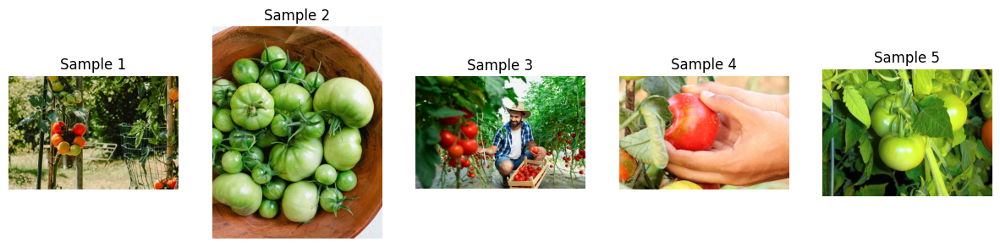

In [8]:
visualize_samples(images)

Let's calculate and visualize the average height and width of the images in the dataset.

In [9]:
def calculate_average_size(images_dir):
    total_width = 0
    total_height = 0
    total_images = 0

    for filename in os.listdir(images_dir):
        if filename.endswith('.jpeg'):  # assuming images are in .jpeg format
            image_path = os.path.join(images_dir, filename)
            image = Image.open(image_path)
            width, height = image.size
            total_width += width
            total_height += height
            total_images += 1
    
    if total_images > 0:
        average_width = total_width / total_images
        average_height = total_height / total_images
        return average_width, average_height
    else:
        return None

In [10]:
def plot_average_size(average_width, average_height):
    categories = ['Average Width', 'Average Height']
    values = [average_width, average_height]

    plt.figure(figsize=(6, 4))
    plt.bar(categories, values, color=['skyblue', 'lightgreen'])
    plt.xlabel('Categories')
    plt.ylabel('Pixels')
    plt.title('Average Image Dimensions')
    plt.ylim(0, max(values) * 1.1)
    plt.grid(axis='y')
    plt.show()

Average Image Width: 1374.88 pixels
Average Image Height: 991.36 pixels


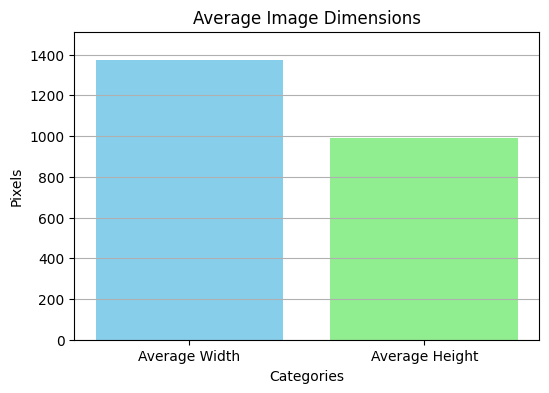

In [11]:
average_width, average_height = calculate_average_size(images_dir)
    
if average_width and average_height:
    print(f"Average Image Width: {average_width:.2f} pixels")
    print(f"Average Image Height: {average_height:.2f} pixels")

    # Plot average size
    plot_average_size(average_width, average_height)
else:
    print("No images found or unable to calculate average size.")

We are also going to plot the distribution of classes ('ripe' and 'unripe') so, let's create a seperate function for this.

In [12]:
def plot_class_distribution(annotations):
    classes = {'ripe': 0, 'unripe': 0}
    
    for annotation_file in annotations:
        with open(annotation_file, 'r') as f:
            lines = f.readlines()
            for line in lines:
                class_label = line.split()[0]  # assuming YOLO format with class label as first entry
                if class_label == '0':
                    classes['unripe'] += 1
                elif class_label == '1':
                    classes['ripe'] += 1
    # Print the class counts
    for cls, count in classes.items():
        print(f"{cls}: {count}")
    
    # Plotting
    plt.bar(classes.keys(), classes.values())
    plt.title('Class Distribution')
    plt.xlabel('Class')
    plt.ylabel('Count')
    plt.show()

ripe: 429
unripe: 440


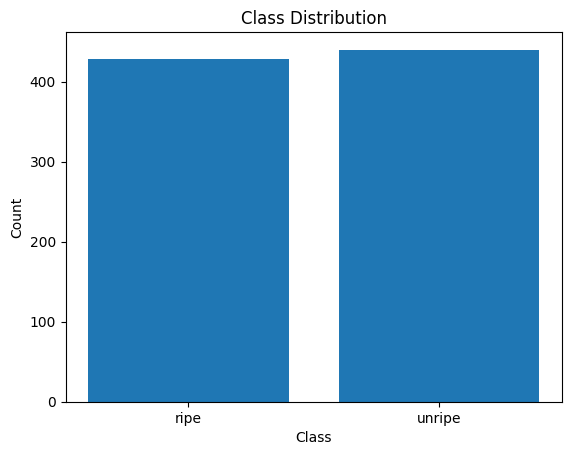

In [13]:
plot_class_distribution(annotations)

Let's explore the RGB distributions of our datasets. Generally, the ripe tomatoes will have higher intensity in the red channel, whereas unripe tomatoes might have higher intensity in the green channel.

In [14]:
from glob import glob

In [15]:
def read_annotations(annotation_path):
    with open(annotation_path, 'r') as file:
        return file.read().strip()

In [16]:
def read_image(img_path):
    img = cv2.imread(img_path)
    if img is not None:
        return img
    return np.array([])

In [17]:
def process_images_in_batches(images, max_images=50, batch_size=10):
    """Process images in batches to reduce memory usage."""
    r_values, g_values, b_values = [], [], []
    
    # Limit the number of images to max_images
    images = images[:max_images]
    
    for i in range(0, len(images), batch_size):
        batch = images[i:i + batch_size]
        with ThreadPoolExecutor() as executor:
            img_list = list(executor.map(read_image, batch))
        
        for img in img_list:
            if img.size > 0:
                r_values.extend(img[:, :, 0].flatten())
                g_values.extend(img[:, :, 1].flatten())
                b_values.extend(img[:, :, 2].flatten())
                
    return r_values, g_values, b_values

def plot_rgb_distribution(images, category_name, max_images=50, batch_size=10):
    """Plot RGB distribution for the given images."""
    r_values, g_values, b_values = process_images_in_batches(images, max_images, batch_size)
    
    plt.figure(figsize=(15, 5))
    
    # Red Channel
    plt.subplot(1, 3, 1)
    r_hist, r_bins = np.histogram(r_values, bins=256, range=(0, 256))
    plt.bar(r_bins[:-1], r_hist, width=1, color='red', alpha=0.5)
    max_r_freq = r_hist.max()
    plt.axhline(max_r_freq, color='red', linestyle='--', label=f'Max Frequency: {max_r_freq}')
    plt.title(f'{category_name} - Red Channel')
    plt.xlabel('Pixel Value')
    plt.ylabel('Frequency')
    plt.legend()
    
    # Green Channel
    plt.subplot(1, 3, 2)
    g_hist, g_bins = np.histogram(g_values, bins=256, range=(0, 256))
    plt.bar(g_bins[:-1], g_hist, width=1, color='green', alpha=0.5)
    max_g_freq = g_hist.max()
    plt.axhline(max_g_freq, color='green', linestyle='--', label=f'Max Frequency: {max_g_freq}')
    plt.title(f'{category_name} - Green Channel')
    plt.xlabel('Pixel Value')
    plt.ylabel('Frequency')
    plt.legend()
    
    # Blue Channel
    plt.subplot(1, 3, 3)
    b_hist, b_bins = np.histogram(b_values, bins=256, range=(0, 256))
    plt.bar(b_bins[:-1], b_hist, width=1, color='blue', alpha=0.5)
    max_b_freq = b_hist.max()
    plt.axhline(max_b_freq, color='blue', linestyle='--', label=f'Max Frequency: {max_b_freq}')
    plt.title(f'{category_name} - Blue Channel')
    plt.xlabel('Pixel Value')
    plt.ylabel('Frequency')
    plt.legend()
    
    plt.tight_layout()
    plt.show()

In [18]:
# Separate ripe and unripe tomatoes based on annotations
ripe_images = []
unripe_images = []

for img_path, annotation_path in zip(images, annotations):
    annotation = read_annotations(annotation_path)
    if annotation.startswith('1'):
        ripe_images.append(img_path)
    elif annotation.startswith('0'):
        unripe_images.append(img_path)

In [19]:
# Debugging: Print the number of images in each category
print(f"Number of ripe images: {len(ripe_images)}")
print(f"Number of unripe images: {len(unripe_images)}")


Number of ripe images: 91
Number of unripe images: 86


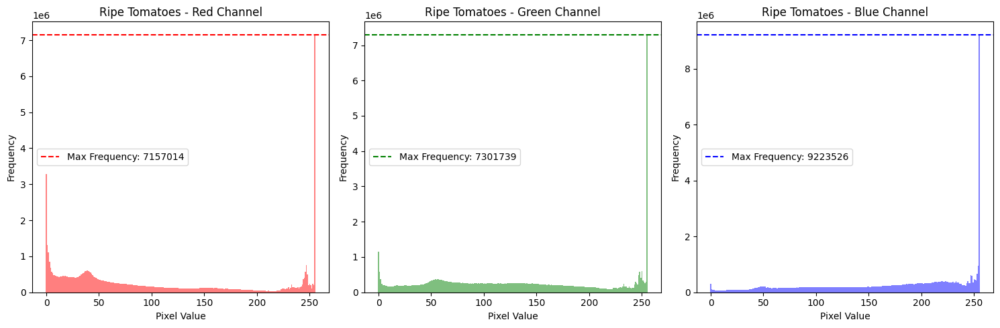

In [20]:
# Plot RGB distribution for ripe tomatoes
plot_rgb_distribution(ripe_images, 'Ripe Tomatoes')

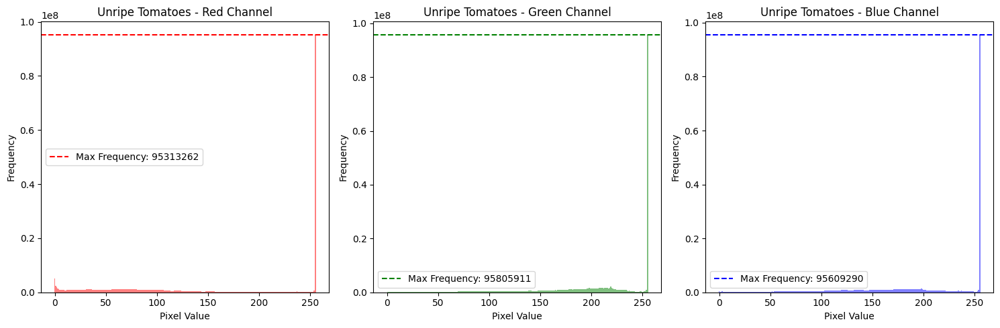

In [21]:
# Plot RGB distribution for unripe tomatoes
plot_rgb_distribution(unripe_images, 'Unripe Tomatoes')

From above, we can see that the **RED** color distribution is higher for ripe tomatoes whereas **Green** for unripe ones, indicating that ripe tomatoes have stronger presenence of red color in their images and green color for unripe ones. Lets apply various edge detection technique and see which better captures the tomato features.

* **Adaptive Thresholding**: Enhances contrast to highlight edges.
* **Laplacian Detection**: Detects rapid intensity changes.
* **Canny Detection**: Identifies detailed edges through gradient analysis.
* **Sobel Detection**: Finds edges using gradient in x and y directions.

In [22]:
def calculate_edge_density(edges):
    return np.sum(edges) / edges.size

In [23]:
def display_random_images_with_edges(basefolder, num_images=5):
    # Define image folder path and get list of image files
    image_folder = basefolder
    image_files = glob(os.path.join(image_folder, "*.jpeg"))
    
    # Check if there are enough images to display
    if len(image_files) < num_images:
        print(f"Not enough images in {image_folder} to display {num_images}.")
        return
    
    # Randomly select images
    selected_images = random.sample(image_files, num_images)
    
    # Create subplots to display the images
    fig, axes = plt.subplots(num_images, 5, figsize=(20, 4 * num_images))
    
    for idx, image_file in enumerate(selected_images):
        # Read and preprocess the image
        img_path = os.path.join(image_folder, image_file)
        img = cv2.imread(img_path)
        img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        gray_img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
        
        # Apply various edge detection techniques
        # Adaptive Thresholding
        adaptive_thresh = cv2.adaptiveThreshold(gray_img, 255, cv2.ADAPTIVE_THRESH_MEAN_C, cv2.THRESH_BINARY, 11, 3)

        # Laplacian Edge Detection
        lap = cv2.Laplacian(gray_img, cv2.CV_64F)
        lap = np.uint8(np.absolute(lap))
        lap_rgb = cv2.cvtColor(lap, cv2.COLOR_GRAY2RGB)

        # Canny Edge Detection
        mean_intensity = np.mean(gray_img)
        std_intensity = np.std(gray_img)
        lower_threshold = int(max(0, mean_intensity - 2 * std_intensity))
        upper_threshold = int(min(255, mean_intensity + 2 * std_intensity))
        edges = cv2.Canny(gray_img, lower_threshold, upper_threshold)

        # Sobel Edge Detection
        sobelx = cv2.Sobel(gray_img, cv2.CV_64F, 1, 0)
        sobely = cv2.Sobel(gray_img, cv2.CV_64F, 0, 1)
        combined_sobel = cv2.bitwise_or(cv2.convertScaleAbs(sobelx), cv2.convertScaleAbs(sobely))
        combined_sobel_rgb = cv2.cvtColor(combined_sobel, cv2.COLOR_GRAY2RGB)

        # Display Original Image
        axes[idx, 0].imshow(img_rgb)
        axes[idx, 0].set_title('Original')
        axes[idx, 0].axis('off')

        # Display Adaptive Thresholded Image
        axes[idx, 1].imshow(adaptive_thresh, cmap='gray')
        axes[idx, 1].set_title('Adaptive Threshold')
        axes[idx, 1].axis('off')

        # Display Laplacian Edge Detection Image
        axes[idx, 2].imshow(lap_rgb)
        axes[idx, 2].set_title('Laplacian')
        axes[idx, 2].axis('off')

        # Display Canny Edge Detection Image
        axes[idx, 3].imshow(edges, cmap='gray')
        axes[idx, 3].set_title('Canny')
        axes[idx, 3].axis('off')

        # Display Sobel Edge Detection Image
        axes[idx, 4].imshow(combined_sobel_rgb)
        axes[idx, 4].set_title('Sobel')
        axes[idx, 4].axis('off')

    # Adjust layout and show plot
    plt.tight_layout()
    plt.show()

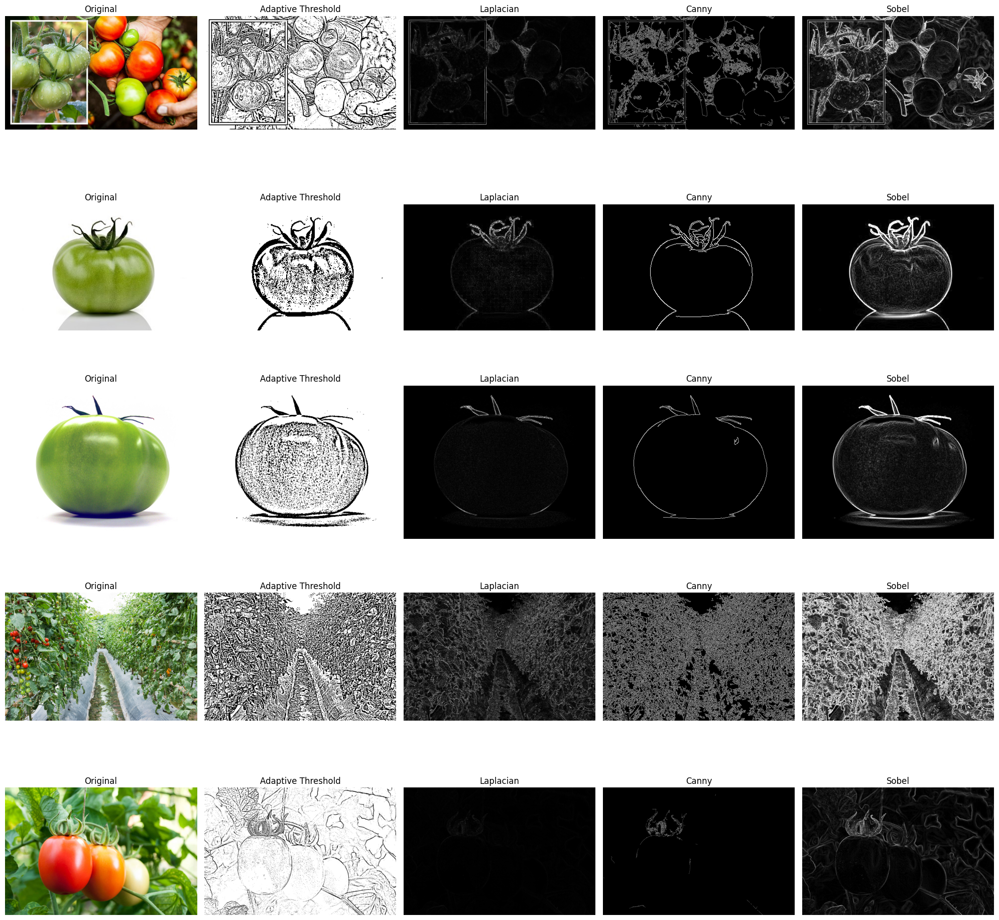

In [24]:
display_random_images_with_edges(images_dir, num_images=5)

Let's compare the edge density of above edge detection. For this, we will plot the frequency vs edge density of the above applied techniques.

In [25]:
def display_edge_density(basefolder, num_images=5):
    image_files = glob(os.path.join(basefolder, "*.jpeg"))
    if len(image_files) < num_images:
        print(f"Not enough images in {basefolder} to display {num_images}.")
        return

    selected_images = random.sample(image_files, num_images)
    densities = {'Adaptive Threshold': [], 'Laplacian': [], 'Canny': [], 'Sobel': []}
    
    for img_file in selected_images:
        img_path = os.path.join(basefolder, img_file)
        img = cv2.imread(img_path)
        gray_img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
        
        # Adaptive Thresholding
        adaptive_thresh = cv2.adaptiveThreshold(gray_img, 255, cv2.ADAPTIVE_THRESH_MEAN_C, cv2.THRESH_BINARY, 11, 3)
        densities['Adaptive Threshold'].append(calculate_edge_density(adaptive_thresh))

        # Laplacian Edge Detection
        lap = cv2.Laplacian(gray_img, cv2.CV_64F)
        lap = np.uint8(np.absolute(lap))
        densities['Laplacian'].append(calculate_edge_density(lap))

        # Canny Edge Detection
        mean_intensity = np.mean(gray_img)
        std_intensity = np.std(gray_img)
        lower_threshold = int(max(0, mean_intensity - 2 * std_intensity))
        upper_threshold = int(min(255, mean_intensity + 2 * std_intensity))
        edges = cv2.Canny(gray_img, lower_threshold, upper_threshold)
        densities['Canny'].append(calculate_edge_density(edges))

        # Sobel Edge Detection
        sobelx = cv2.Sobel(gray_img, cv2.CV_64F, 1, 0)
        sobely = cv2.Sobel(gray_img, cv2.CV_64F, 0, 1)
        combined_sobel = cv2.bitwise_or(cv2.convertScaleAbs(sobelx), cv2.convertScaleAbs(sobely))
        densities['Sobel'].append(calculate_edge_density(combined_sobel))

    # Plot the average edge densities for each method
    plt.figure(figsize=(12, 6))
    for method, density_values in densities.items():
        plt.hist(density_values, bins=10, alpha=0.5, label=method)
    
    plt.title('Edge Density Comparison')
    plt.xlabel('Edge Density')
    plt.ylabel('Frequency')
    plt.legend()
    plt.show()

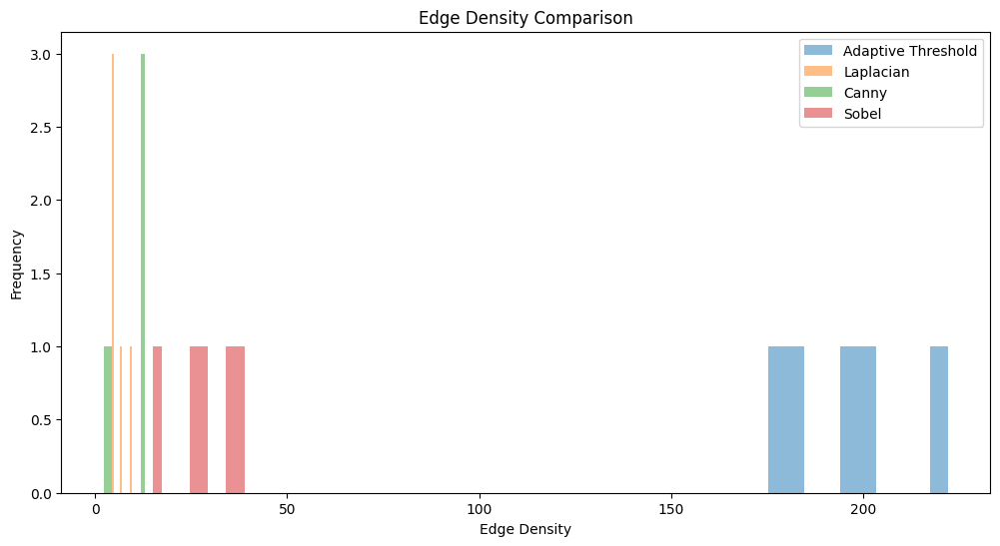

In [26]:
display_edge_density(images_dir, num_images=5)

From the above, we can see the frequency and edge density of each technique. For detecting finer details or stronger edges, higher frequencies are better.

To count the number of images containing both 'ripe' and 'unripe' tomatoes let's create a count_mixed_images function that takes list of annotations as an arguments.

In [27]:
def count_mixed_images(annotations):
    mixed_images_count = 0
    
    for annotation_file in annotations:
        with open(annotation_file, 'r') as f:
            lines = f.readlines()
            has_ripe = False
            has_unripe = False
            for line in lines:
                class_label = int(line.split()[0])
                if class_label == 0:
                    has_unripe = True
                elif class_label == 1:
                    has_ripe = True
            if has_ripe and has_unripe:
                mixed_images_count += 1
    
    return mixed_images_count

In [28]:
mixed_images_count = count_mixed_images(annotations)

print(f"Mixed Images Count: {mixed_images_count}")

Mixed Images Count: 33


To plot the count of images containing both 'ripe' and 'unripe' tomatoes. Let's have a seperate function.

In [29]:
def plot_mixed_images_count(mixed_images_count):
    categories = ['Mixed Images']
    counts = [mixed_images_count]

    plt.figure(figsize=(6, 4))
    plt.bar(categories, counts, color='skyblue')
    plt.xlabel('Categories')
    plt.ylabel('Number of Images')
    plt.title('Images Containing Both Ripe and Unripe Tomatoes')
    plt.ylim(0, max(counts) * 1.1)
    plt.grid(axis='y')
    plt.show()

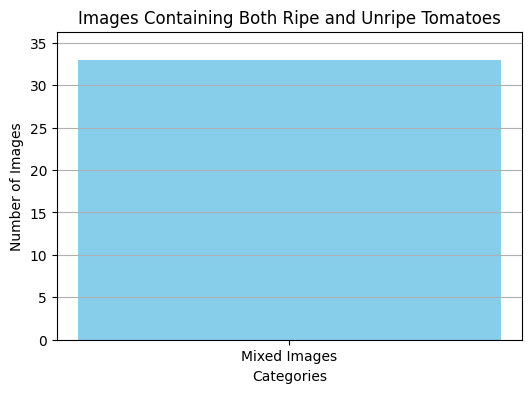

In [30]:
# Plotting mixed images count
plot_mixed_images_count(mixed_images_count)

The dataset contains images that has both ripe and unripe tomatoes so, let's create a function to find and display sample images that has both.

In [31]:
def show_sample_mixed_images(images_dir, labels_dir, num_samples=3):
    # Load dataset
    images, annotations = load_data(images_dir, labels_dir)
    
    # Initialize a list to store paths of mixed images
    mixed_image_paths = []
    
    # Iterate through annotations to find images with both classes
    for i, annotation_file in enumerate(annotations):
        with open(annotation_file, 'r') as f:
            lines = f.readlines()
            has_ripe = False
            has_unripe = False
            for line in lines:
                class_label = int(line.split()[0])  # assuming YOLO format with class label as first entry
                if class_label == 0:
                    has_unripe = True
                elif class_label == 1:
                    has_ripe = True
            if has_ripe and has_unripe:
                mixed_image_paths.append(images[i])
                
        # Stop when enough samples are found
        if len(mixed_image_paths) >= num_samples:
            break
    
    # Display sample images
    if mixed_image_paths:
        plt.figure(figsize=(15, 6))
        for i, image_path in enumerate(random.sample(mixed_image_paths, num_samples)):
            image = Image.open(image_path)
            plt.subplot(1, num_samples, i + 1)
            plt.imshow(image)
            plt.axis('off')
            plt.title(f'Sample {i+1}')
        plt.tight_layout()
        plt.show()
    else:
        print("No images found with both ripe and unripe tomatoes.")

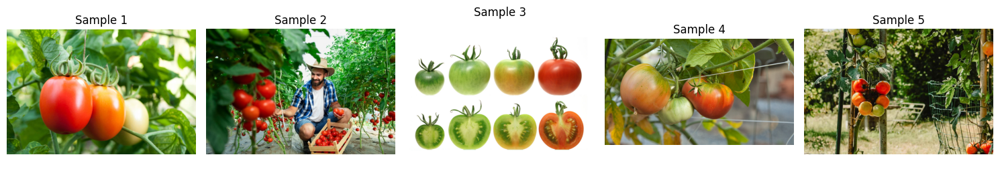

In [32]:
show_sample_mixed_images(images_dir, labels_dir, num_samples=5)

To draw the bounding boxes on an image based on annotations, we will be using draw_bounding_boxes function.

In [33]:
def draw_bounding_boxes(image_path, annotation_path):
    image = Image.open(image_path)
    draw = ImageDraw.Draw(image)
    with open(annotation_path, 'r') as f:
        for line in f:
            class_label, x_center, y_center, width, height = map(float, line.strip().split())
            # Convert YOLO format to bounding box coordinates
            img_width, img_height = image.size
            x_center *= img_width
            y_center *= img_height
            width *= img_width
            height *= img_height
            x_min = x_center - (width / 2)
            x_max = x_center + (width / 2)
            y_min = y_center - (height / 2)
            y_max = y_center + (height / 2)
            # Draw rectangle
            if class_label == 0:
                color = 'green'  # unripe
            else:
                color = 'red'  # ripe
            draw.rectangle([x_min, y_min, x_max, y_max], outline=color, width=2)
    return image

Since it's possible to have both ripe and unripe tomatoes in a single image, let's create a function to display these images with bounding boxes.

In [34]:
def show_sample_mixed_images_with_bounding_boxes(images_dir, labels_dir, num_samples=3):
    # Load dataset
    images, annotations = load_data(images_dir, labels_dir)
    
    # Initialize a list to store paths of mixed images
    mixed_image_paths = []
    
    # Iterate through annotations to find images with both classes
    for i, annotation_file in enumerate(annotations):
        with open(annotation_file, 'r') as f:
            lines = f.readlines()
            has_ripe = False
            has_unripe = False
            for line in lines:
                class_label = int(line.split()[0])  # assuming YOLO format with class label as first entry
                if class_label == 0:
                    has_unripe = True
                elif class_label == 1:
                    has_ripe = True
            if has_ripe and has_unripe:
                mixed_image_paths.append((images[i], annotations[i]))
                
        # Stop when enough samples are found
        if len(mixed_image_paths) >= num_samples:
            break
    
    # Display sample images
    if mixed_image_paths:
        plt.figure(figsize=(15, 6))
        for i, (image_path, annotation_path) in enumerate(random.sample(mixed_image_paths, num_samples)):
            original_image = Image.open(image_path)
            annotated_image = draw_bounding_boxes(image_path, annotation_path)
            
            plt.subplot(2, num_samples, i + 1)
            plt.imshow(original_image)
            plt.axis('off')
            plt.title(f'Original {i+1}')
            
            plt.subplot(2, num_samples, num_samples + i + 1)
            plt.imshow(annotated_image)
            plt.axis('off')
            plt.title(f'Annotated {i+1}')
            
        plt.tight_layout()
        plt.show()
    else:
        print("No images found with both ripe and unripe tomatoes.")

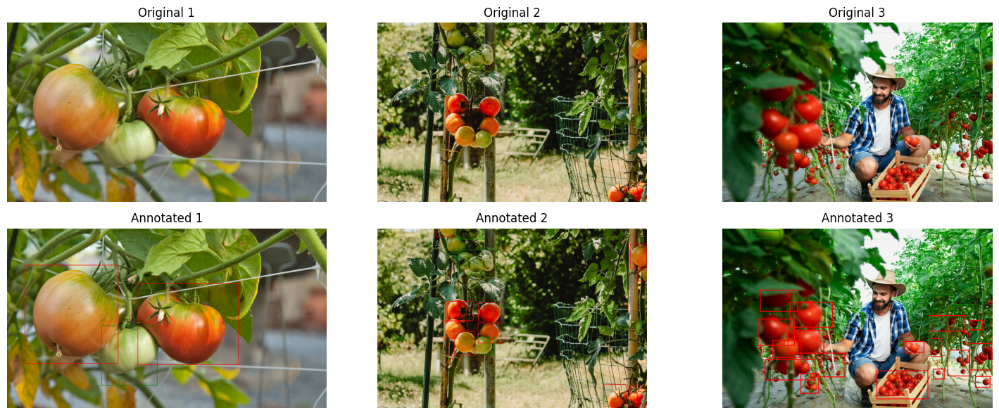

In [35]:
show_sample_mixed_images_with_bounding_boxes(images_dir, labels_dir, num_samples=3)

In [36]:
# Handle potential train/test subdirectories
working_dir = os.path.join("/kaggle","working")
train_images_dir = os.path.join(working_dir, "train", "images")
train_labels_dir = os.path.join(working_dir, "train", 'labels')
test_images_dir = os.path.join(working_dir,"test", 'images')
test_labels_dir = os.path.join(working_dir, "test", 'labels')

print(f"Train Images Dir: {train_images_dir}, Train Labels Dir: {train_labels_dir}")
print(f"Test Images Dir: {test_images_dir}, Test Labels Dir: {test_labels_dir}")

Train Images Dir: /kaggle/working/train/images, Train Labels Dir: /kaggle/working/train/labels
Test Images Dir: /kaggle/working/test/images, Test Labels Dir: /kaggle/working/test/labels


In [37]:
# Create train/test directories if they don't exist (using os.makedirs with exist_ok=True)
os.makedirs(train_images_dir, exist_ok=True)
os.makedirs(train_labels_dir, exist_ok=True)
os.makedirs(test_images_dir, exist_ok=True)
os.makedirs(test_labels_dir, exist_ok=True)

Now that we have created the respective folders, let's start importing the images.

In [38]:
# Get list of images and labels
images = [f for f in os.listdir(images_dir) if f.endswith('.jpeg')]
labels = [f.replace('.jpeg', '.txt') for f in images]

Let's preview the number of images and labels we have.

In [39]:
print(f"Images Length: {len(images)}")
print(f"Labels Length: {len(labels)}")

Images Length: 177
Labels Length: 177


We have an equal number of images and labels. Now, we will split the dataset, where the training set will contain `80%` of the images and the remaining `20%` will be in the test set.

In [40]:
# Split into training and testing sets
train_images, test_images = train_test_split(images, test_size=0.2, random_state=42)
train_labels = [f.replace('.jpeg', '.txt') for f in train_images]
test_labels = [f.replace('.jpeg', '.txt') for f in test_images]
print(f"Training set: {len(train_images)} images, {len(train_labels)} labels")
print(f"Testing set: {len(test_images)} images, {len(test_labels)} labels")

Training set: 141 images, 141 labels
Testing set: 36 images, 36 labels


After splitting the dataset, let's move the files to their respective folders.

In [41]:
# Copy files to the respective directories
def copy_files(file_list, src_path, dst_path):
    for file in file_list:
        shutil.copy(os.path.join(src_path, file), os.path.join(dst_path, file))

In [42]:
copy_files(train_images, images_dir, train_images_dir)
copy_files(train_labels, labels_dir, train_labels_dir)
copy_files(test_images, images_dir, test_images_dir)
copy_files(test_labels, labels_dir, test_labels_dir)


In [43]:
def calculate_iou(box1, box2):
    x1, y1, w1, h1 = box1
    x2, y2, w2, h2 = box2

    xi1 = max(x1, x2)
    yi1 = max(y1, y2)
    xi2 = min(x1 + w1, x2 + w2)
    yi2 = min(y1 + h1, y2 + h2)

    inter_area = max(0, xi2 - xi1) * max(0, yi2 - yi1)
    box1_area = w1 * h1
    box2_area = w2 * h2

    union_area = box1_area + box2_area - inter_area

    return inter_area / union_area

In [44]:
def calculate_iou(box1, box2):
    xi1 = max(box1[0], box2[0])
    yi1 = max(box1[1], box2[1])
    xi2 = min(box1[2], box2[2])
    yi2 = min(box1[3], box2[3])

    inter_area = max(0, xi2 - xi1) * max(0, yi2 - yi1)
    box1_area = (box1[2] - box1[0]) * (box1[3] - box1[1])
    box2_area = (box2[2] - box2[0]) * (box2[3] - box2[1])

    union_area = box1_area + box2_area - inter_area
    return inter_area / union_area if union_area != 0 else 0

def convert_yolo_to_bbox(yolo_bbox, img_width, img_height):
    x_center, y_center, width, height = yolo_bbox
    x_min = (x_center - width / 2) * img_width
    x_max = (x_center + width / 2) * img_width
    y_min = (y_center - height / 2) * img_height
    y_max = (y_center + height / 2) * img_height
    return [x_min, y_min, x_max, y_max]


ious = []

for annotation_file in annotations:
    with open(annotation_file, 'r') as file:
        lines = file.readlines()
        boxes = []
        for line in lines:
            _, x_center, y_center, width, height = map(float, line.split())
            bbox = convert_yolo_to_bbox([x_center, y_center, width, height], img_width=average_width, img_height=average_height)
            boxes.append(bbox)
        # Calculate IoU for every pair of boxes in the same image
        for i in range(len(boxes)):
            for j in range(i + 1, len(boxes)):
                iou = calculate_iou(boxes[i], boxes[j])
                ious.append(iou)

average_iou = np.mean(ious)
print("Average IoU:", average_iou)

Average IoU: 0.021127348493532178


## 2. Model Setup: Installing and Configuring Ultralytics YOLOv8
For our project on detecting ripe and unripe tomatoes, let's install YOLO and verify its functionality.

In [45]:
# setup
%pip install ultralytics
import ultralytics
ultralytics.checks()

Ultralytics 8.4.190 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
Setup complete ✅ (4 CPUs, 31.3 GB RAM, 7108.1/8156.9 GB disk)


Next, let's create a configuration file for YOLO. This file provides information about the dataset and the classes it contains.

In [46]:
dataset_yaml = """
train: /kaggle/working/train/images
val: /kaggle/working/test/images

nc: 2  # number of classes
names: ['unripe', 'ripe']  # class names
"""

with open('/kaggle/working/dataset.yaml', 'w') as file:
    file.write(dataset_yaml)

Let's check the available commands in YOLOv8.

In [47]:
!yolo


    Arguments received: ['yolo']. Ultralytics 'yolo' commands use the following syntax:

        yolo TASK MODE ARGS

        Where   TASK (optional) is one of ['detect', 'segment', 'semantic', 'depth', 'classify', 'pose', 'obb']
                MODE (required) is one of ['train', 'val', 'predict', 'export', 'track', 'benchmark']
                ARGS (optional) are any number of custom 'arg=value' pairs like 'imgsz=320' that override defaults.
                    See all ARGS at https://docs.ultralytics.com/usage/cfg or with 'yolo cfg'

    1. Train a detection model for 10 epochs with an initial learning_rate of 0.01
        yolo train data=coco8.yaml model=yolo26n.pt epochs=10 lr0=0.01

    2. Predict a YouTube video using a pretrained segmentation model at image size 320:
        yolo predict model=yolo26n-seg.pt source='https://youtu.be/LNwODJXcvt4' imgsz=320

    3. Validate a pretrained detection model at batch-size 1 and image size 640:
        yolo val model=yolo26n.pt data=co

## 3. Training YOLOv8 on the Tomato Ripeness Dataset
We will train our model using `150` epochs with a batch size of `16`, and we will set the image size to `640`. The [exploratory data analysis (EDA)](https://www.kaggle.com/code/sumn2u/eda-of-ripe-and-unripe-tomatoes-dataset/notebook) shows more information about images and their sizes.

In [48]:
from ultralytics import YOLO
from IPython.display import Image, display

model = YOLO('yolov8m.pt')
data_yaml_path = "/kaggle/working/dataset.yaml"

results = model.train(
    data=data_yaml_path,
    epochs=10,
    imgsz=640,
    device=[0,1],
    
    # ✅ REDUCE aggressive augmentations causing instability
    augment=True,
    hsv_h=0.05,    # ⬇️ Reduce from 0.1 (less color variation)
    hsv_s=0.4,     # ⬇️ Reduce from 0.7
    hsv_v=0.2,     # ⬇️ Reduce from 0.4
    degrees=10.0,  # ⬇️ Reduce from 15.0
    shear=0.0,     # ⬇️ Reduce from 2.0
    mosaic=0.2,    # ⬇️ Reduce from 1.0 (use mosaic 20% of time)
    mixup=0.05,    # ⬇️ Reduce from 0.1 (very little mixup)
    
    # ✅ STABILIZE learning rate
    lr0=0.0002,    # ⬇️ Lower initial LR (MOST IMPORTANT)
    lrf=0.05,       # Gradual decrease to 0.00005
    warmup_epochs=5.0,  # ⬅️ ADD warmup
    warmup_momentum=0.8,
    
    # ✅ Optimizer adjustments
    batch=32,
    momentum=0.9,   # ⬇️ Slightly lower momentum
    weight_decay=0.0005,
    
    # ✅ Disable unstable features
    multi_scale=False,
    amp=True,
    workers=4,
    patience=50,
    save_period=10
)

Ultralytics 8.4.190 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
                                                        CUDA:1 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=True, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/dataset.yaml, degrees=10.0, deterministic=True, device=0,1, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=10, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.05, hsv_s=0.4, hsv_v=0.2, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.0002, lrf=0.05, mask_ratio=4, max_det=300, mixup=0.05, mode=train, model=yolov8m.pt, momentum=0.9, mosaic=0

/usr/local/lib/python3.13/dist-packages/ray/train/_internal/session.py:683: UserWarning: `get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.
  warnings.warn(



      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       2/10      6.81G      2.056      6.205      2.572         35        640: 100% ━━━━━━━━━━━━ 5/5 2.9it/s 1.7s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 1/1 1.6s/it 1.6s
                   all         36        193      0.166     0.0597     0.0387     0.0131

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       3/10      6.81G      2.298      7.748      2.631         35        640: 100% ━━━━━━━━━━━━ 5/5 3.0it/s 1.7s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 1/1 1.5s/it 1.5s
                   all         36        193    0.00216      0.218    0.00318   0.000723

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       4/10      6.81G        2.6      7.438      2.969         23        640: 100% ━━━━━━━━━━━━ 5/5 3.0it/

As demonstrated by these results, the model did not complete the full number of epochs because validation performance stopped improving and training was halted. This technique, known as early stopping, helps maximize generalization and prevents the model from overfitting to the training data.

## 4. Evaluating YOLOv8 Detection Accuracy (mAP, Precision, Recall)
Let's plot the testing results and then perform the evaluation on the validation set.

In [49]:
from PIL import Image

In [50]:
tpaths2=[]
for dirname, _, filenames in os.walk('/kaggle/working/runs/detect/train'):
    for filename in filenames:
        if filename[-4:]=='.png' or filename[-4:]=='.jpg':
            tpaths2+=[(os.path.join(dirname, filename))]
tpaths2=sorted(tpaths2)

print(tpaths2[0])

/kaggle/working/runs/detect/train/BoxF1_curve.png


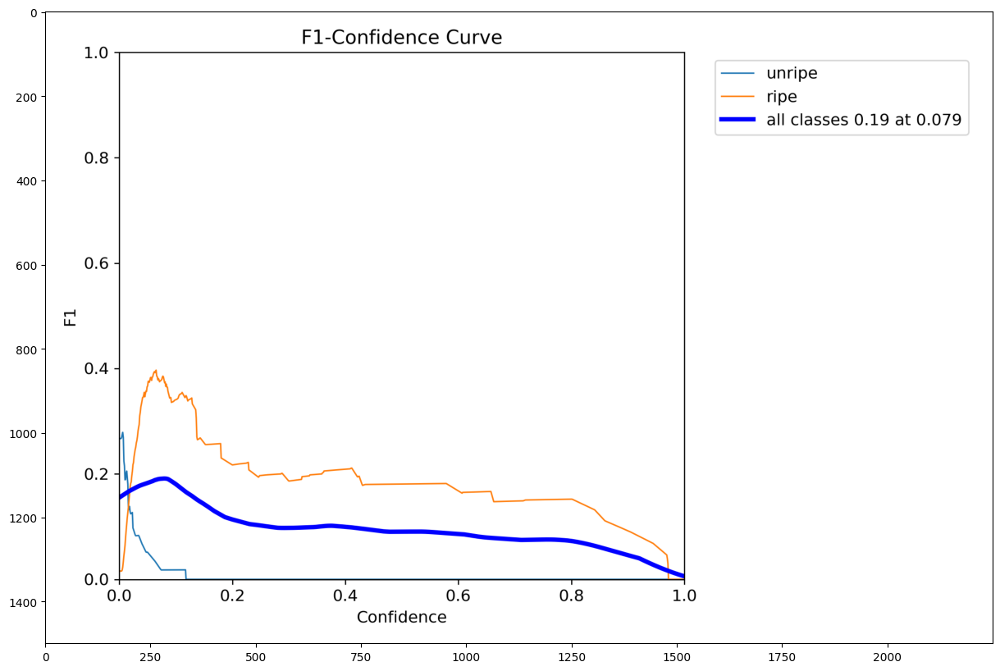

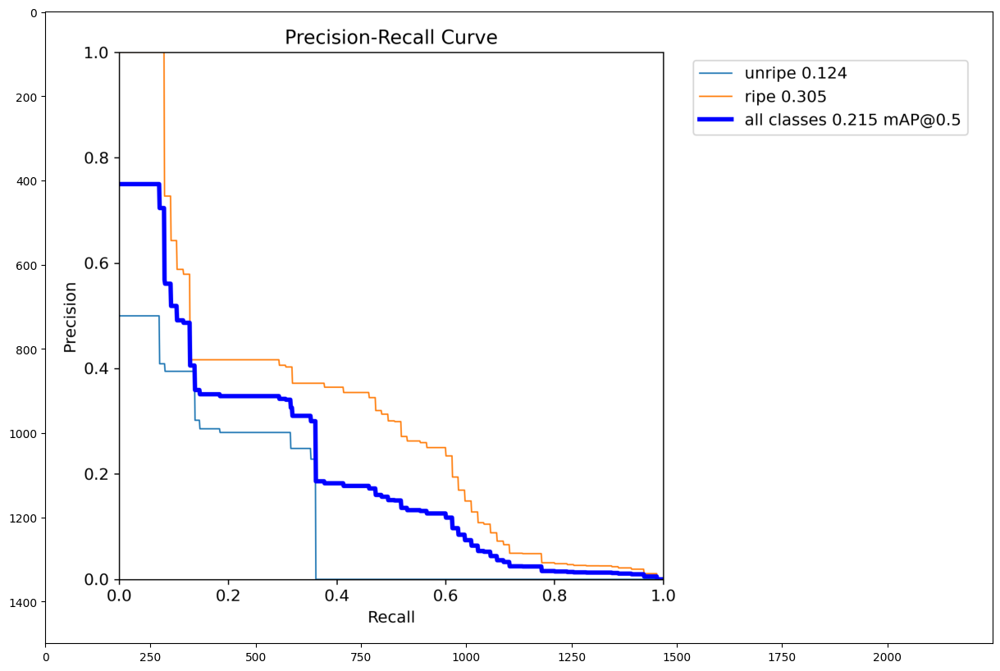

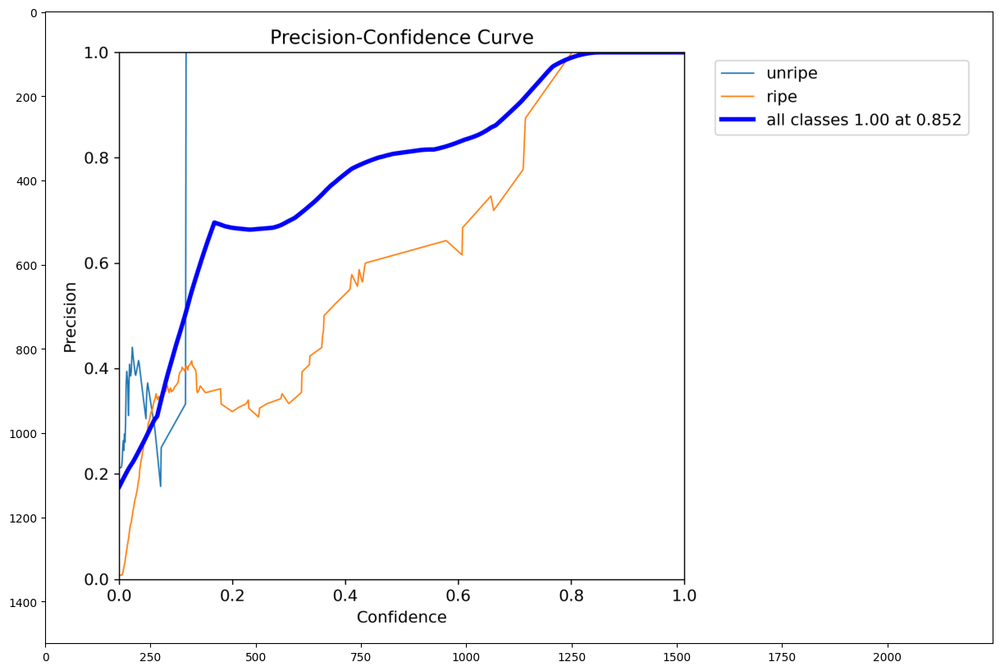

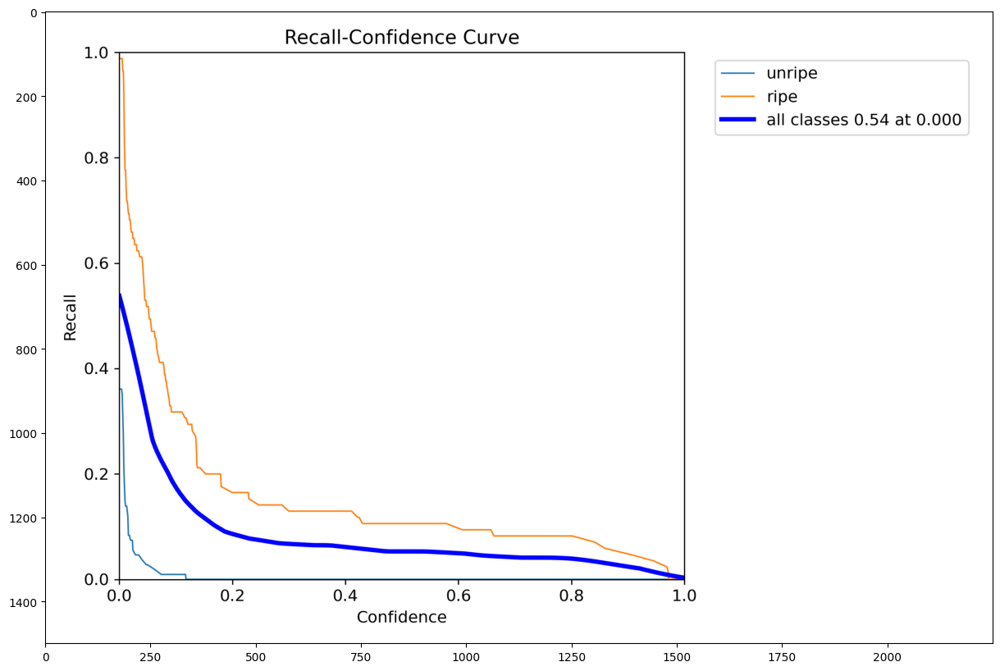

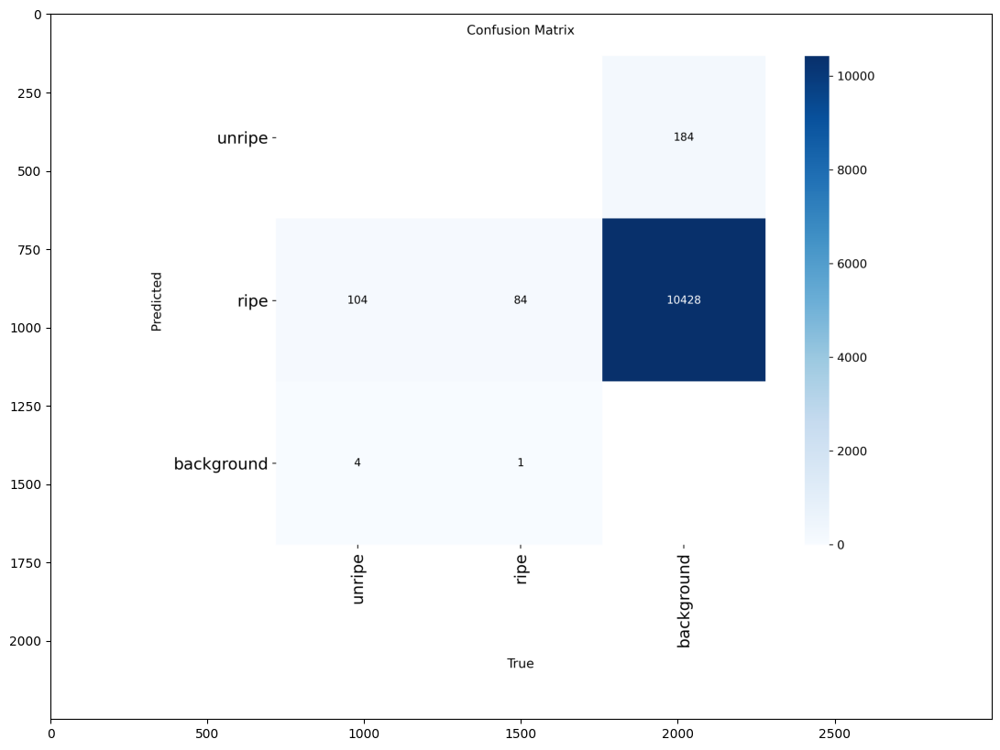

...

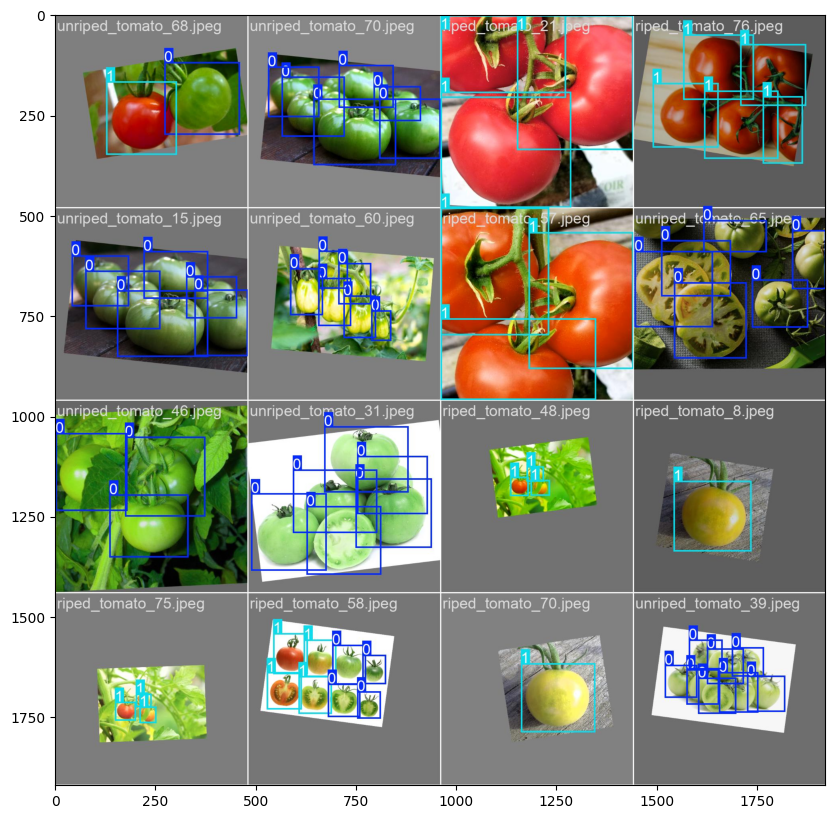

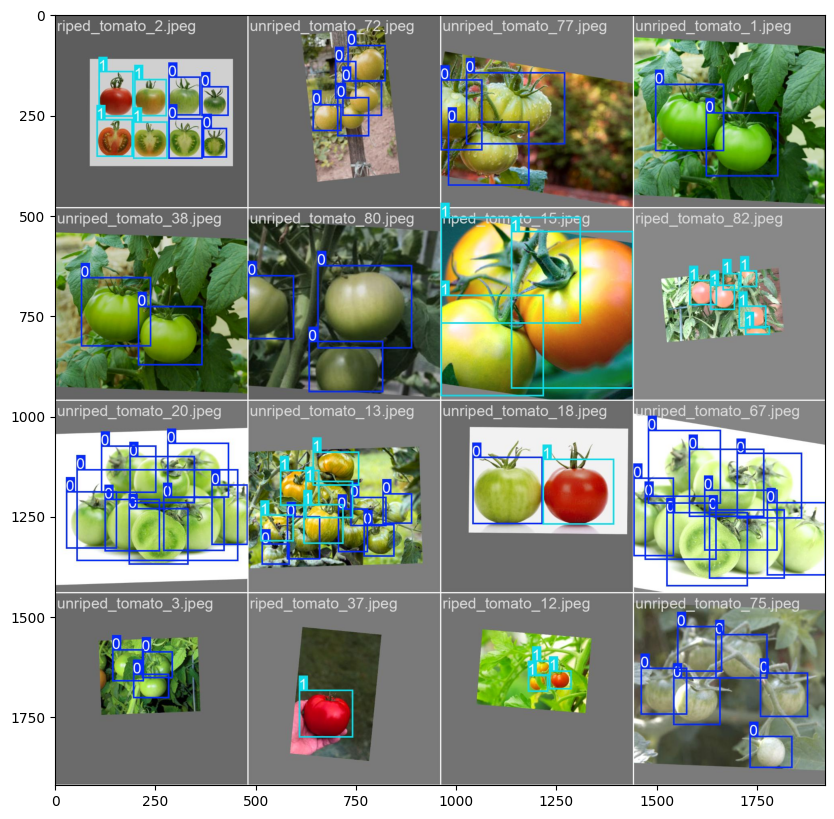

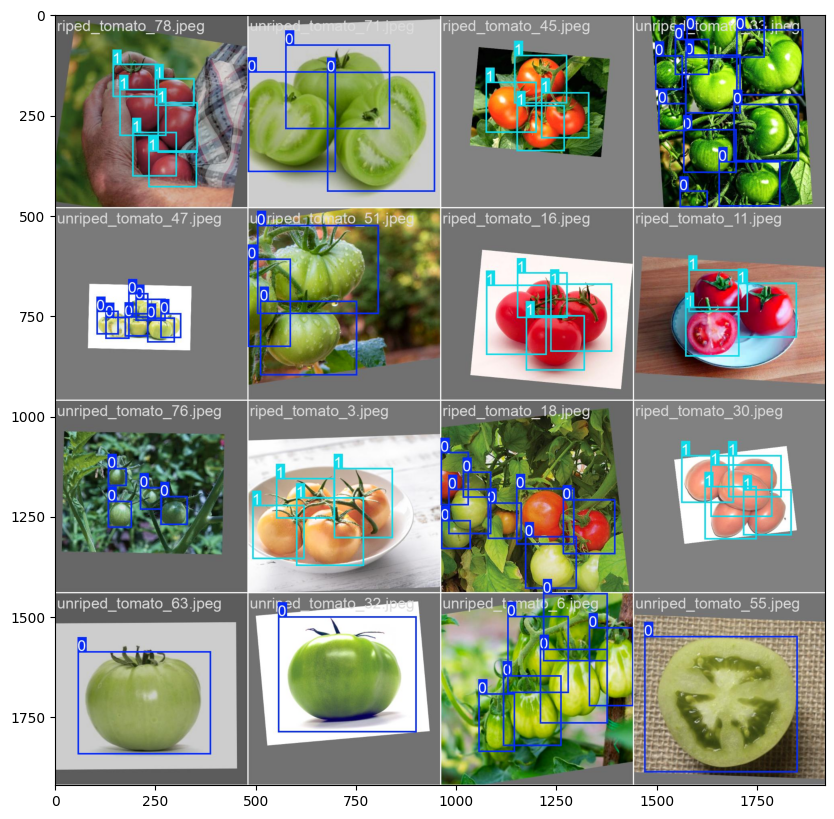

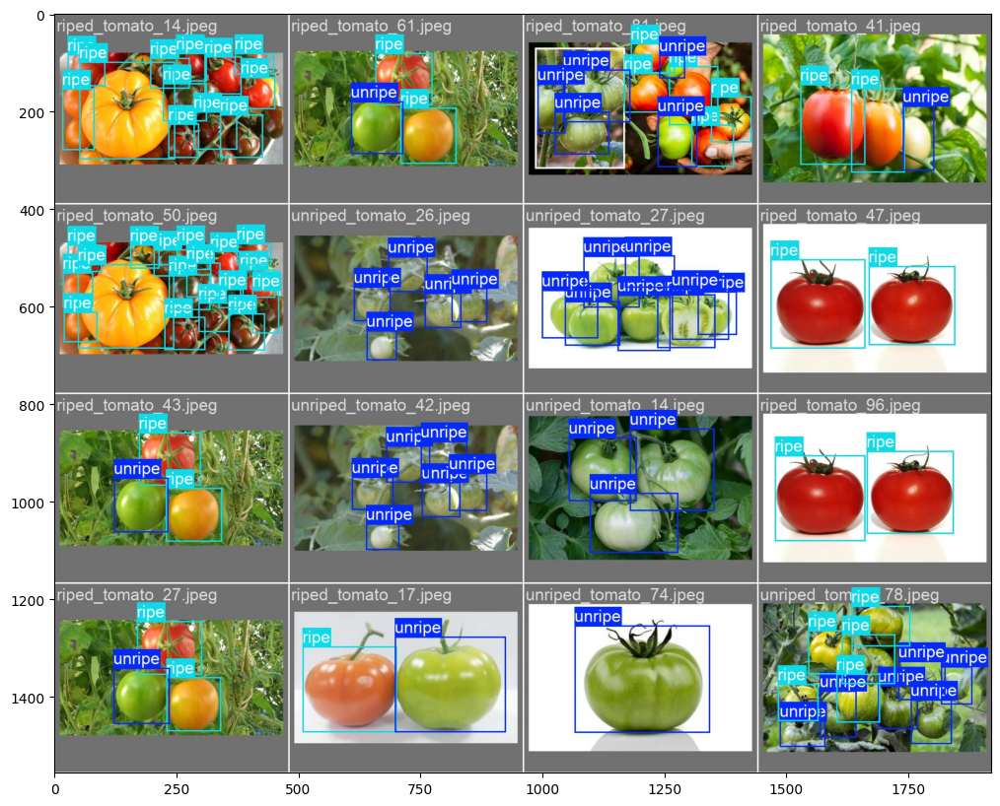

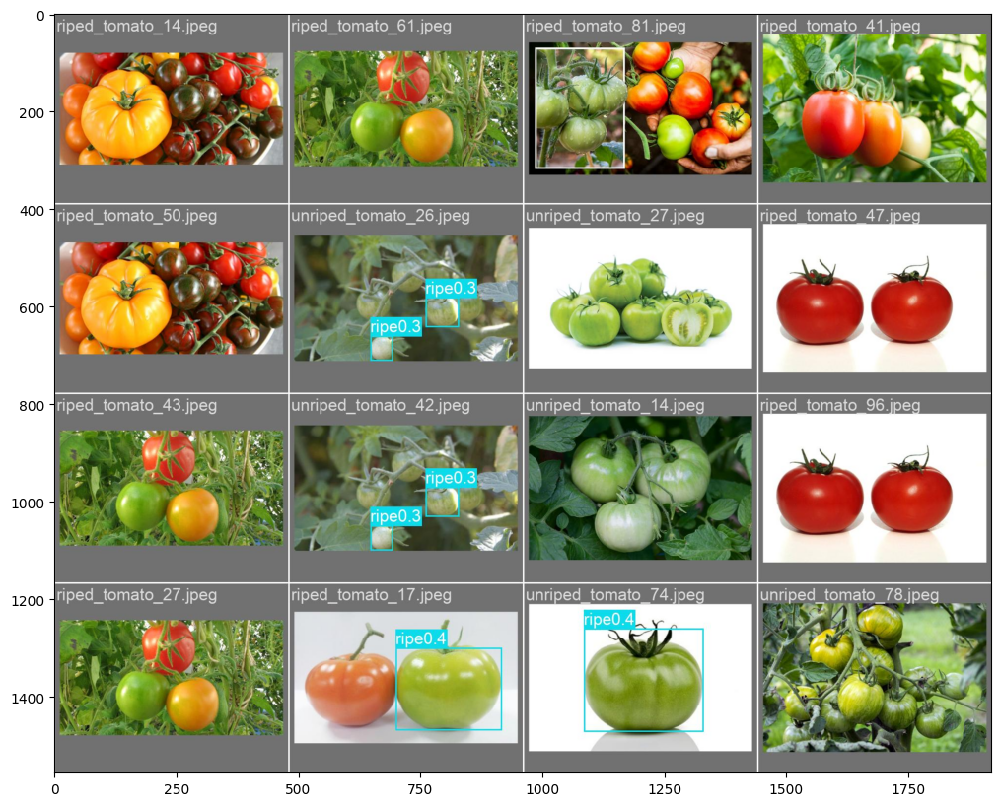

In [51]:
for path in tpaths2:
    image = Image.open(path)
    image=np.array(image)
    plt.figure(figsize=(20,10))
    plt.imshow(image)
    plt.show()


In [52]:
# evaluate model performance on the validation set
results = model.val() 

Ultralytics 8.4.190 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
Model summary (fused): 92 layers, 25,840,918 parameters, 0 gradients, 78.7 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2543.1±609.4 MB/s, size: 177.1 KB)
val: Scanning /kaggle/working/test/labels.cache... 36 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 36/36 7.9Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 3/3 1.8it/s 1.7s
                   all         36        193      0.697      0.237      0.281      0.154
                unripe         28        108          1     0.0277      0.217      0.129
                  ripe         20         85      0.395      0.447      0.346       0.18
Speed: 3.1ms preprocess, 18.6ms inference, 0.0ms loss, 2.4ms postprocess per image
Results saved to /kaggle/working/runs/detect/val


## 5. Running Inference on Test Images

Let's test our model with test images.


image 1/1 /kaggle/working/test/images/unriped_tomato_37.jpeg: 448x640 (no detections), 27.0ms
Speed: 2.6ms preprocess, 27.0ms inference, 0.7ms postprocess per image at shape (1, 3, 448, 640)


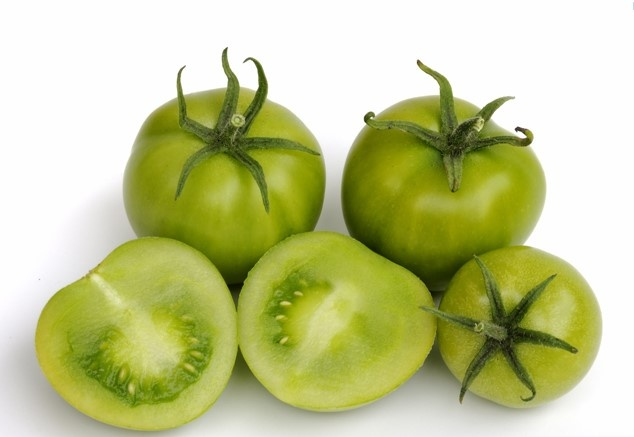


image 1/1 /kaggle/working/test/images/riped_tomato_14.jpeg: 320x640 (no detections), 50.2ms
Speed: 1.7ms preprocess, 50.2ms inference, 0.6ms postprocess per image at shape (1, 3, 320, 640)


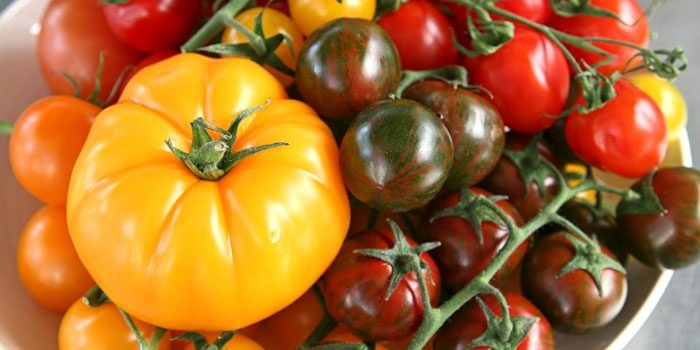

In [53]:
# Define the path to the images
images_path = '/kaggle/working/test/images'
num_images = 2

# Sample a subset of images
images = random.sample([f for f in os.listdir(images_path) if f.endswith('.jpeg')], num_images)

# Show the results on test images 
for image in images:
    img_path = os.path.join(images_path, image)
    results = model(img_path, conf=0.5, iou=0.6)
    r = results[0]
    im_array = r.plot()  # plot a BGR numpy array of predictions

    # Save the image with predictions
    save_path = f'/kaggle/working/{image}'
    cv2.imwrite(save_path, im_array)

    # Display the image
    display(Image.open(save_path))

## 6. Live Demo on Hugging Face Spaces

An application is built using the above model. You can visit it in [![Hugging Face Spaces](https://img.shields.io/badge/🤗%20Hugging%20Face-Spaces-blue)](https://huggingface.co/spaces/iamsuman/ripe-and-unripe-tomatoes-detection).


[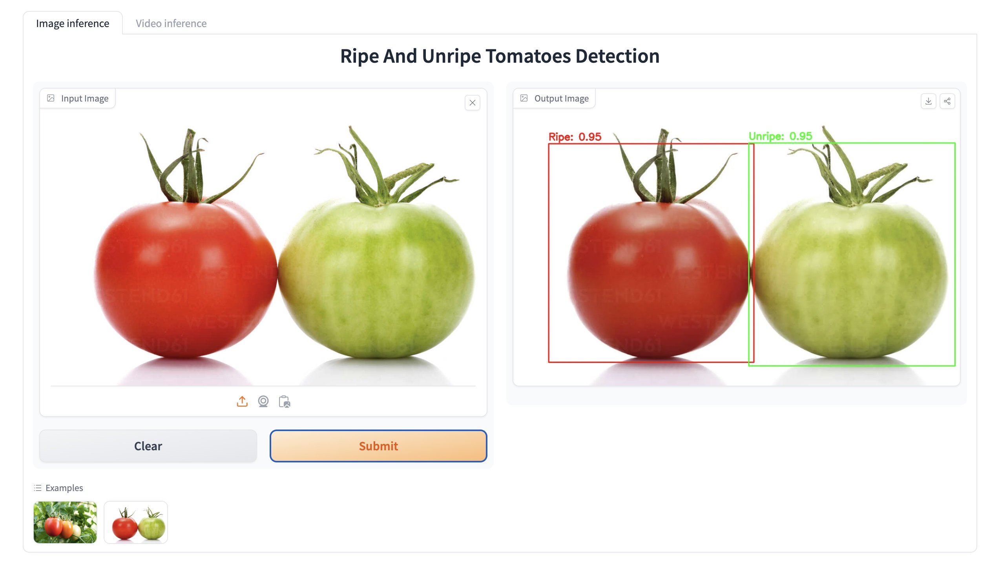](https://huggingface.co/spaces/iamsuman/ripe-and-unripe-tomatoes-detection)


[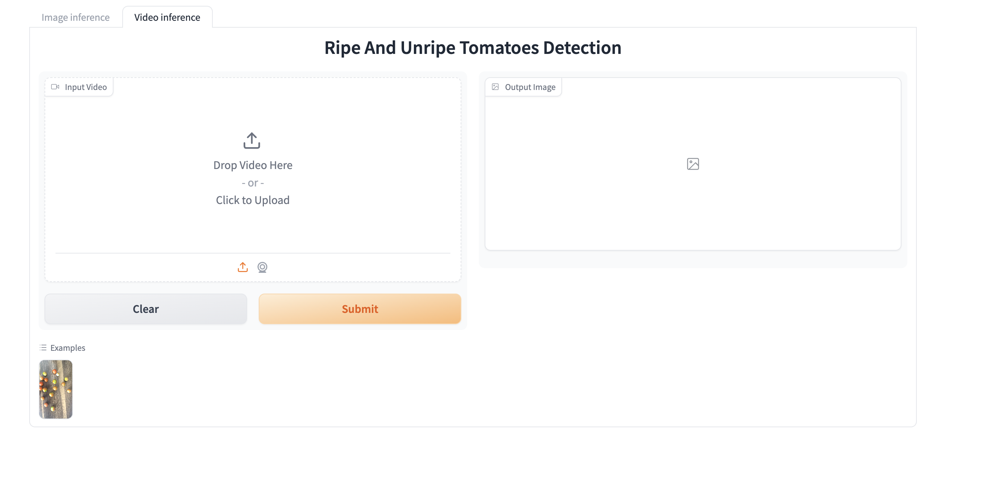](https://huggingface.co/spaces/iamsuman/ripe-and-unripe-tomatoes-detection)




## 7. Exporting YOLOv8 to TFLite and CoreML for Mobile Deployment

We need to export the models as `.tflite` and `.mlmodel` files to ensure they are compatible with mobile and embedded devices. To achieve this, we will use the Ultralytics YOLO CLI for model export.

In [54]:
# Android
!yolo export format=tflite model="/kaggle/working/runs/detect/train/weights/best.pt" imgsz=320 int8 # For detection

# !yolo export format=tflite model=model-cls imgsz=320 int8 # For classification

WARNING ⚠️ 'int8' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ format='tflite' is deprecated as of 8.4.83 and has been replaced by the unified Google LiteRT format. Exporting format='litert' instead. See https://docs.ultralytics.com/integrations/litert
Ultralytics 8.4.190 🚀 Python-3.13.15 torch-2.11.0+cu128 CPU (Intel Xeon CPU @ 2.00GHz)
WARNING ⚠️ INT8 export requires a missing 'data' arg for calibration. Using default 'data=coco8.yaml'.
💡 ProTip: Export to OpenVINO format for best performance on Intel hardware. Learn more at https://docs.ultralytics.com/integrations/openvino
Model summary (fused): 92 layers, 25,840,918 parameters, 0 gradients, 19.7 GFLOPs

PyTorch: starting from '/kaggle/working/runs/detect/train/weights/best.pt' with input shape (1, 3, 320, 320) BCHW and output shape(s) (1, 6, 2100) (49.6 MB)
LiteRT: collecting INT8 calibration images from 'data=coco8.yaml'

WARNING ⚠️ Dataset 'coco8.yaml' images not found, missing path '/kaggl

In [55]:
# iOS
!yolo export format=mlmodel model="/kaggle/working/runs/detect/train/weights/best.pt" imgsz=320,192 half nms

WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
Ultralytics 8.4.190 🚀 Python-3.13.15 torch-2.11.0+cu128 CPU (Intel Xeon CPU @ 2.00GHz)
Model summary (fused): 92 layers, 25,840,918 parameters, 0 gradients, 11.8 GFLOPs

PyTorch: starting from '/kaggle/working/runs/detect/train/weights/best.pt' with input shape (1, 3, 320, 192) BCHW and output shape(s) (1, 6, 1260) (49.6 MB)
requirements: Ultralytics requirement ['coremltools>=9.0'] not found, attempting AutoUpdate...
Using Python 3.13.15 environment at: /usr
Resolved 12 packages in 222ms
 Downloaded coremltools
Prepared 3 packages in 86ms
Uninstalled 1 package in 0.44ms
Installed 3 packages in 17ms
 + cattrs==26.2.1
 + coremltools==9.0
 - typing-extensions==4.12.2
 + typing-extensions==4.16.0

requirements: AutoUpdate success ✅ 0.5s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect

Failed to load /usr/local/lib/python3.13/dist-packages/torchao/_C_cutlass_90a.a

The converted models are passed to flutter app for detection purpose. Source code can be found [here](https://github.com/sumn2u/yolo-flutter-app/tree/main/example).

[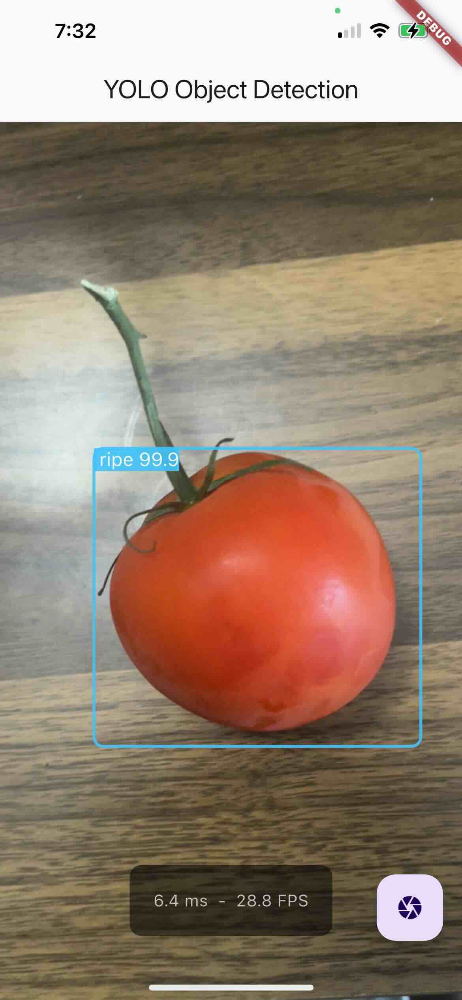](https://github.com/sumn2u/yolo-flutter-app/tree/main/example)


## 8. Model Quantization: FP32 vs FP16 TensorRT Performance

Full-precision models store their weights and computations in 32-bit floating point format, making them large and storage-intensive. To optimize them, we reduce their numerical precision by converting from 32-bit to 8-bit. This reduction enables processors to execute more operations per second, significantly boosting computational efficiency. This process is called quantization: a key optimization technique that enables AI models to do more with less. By reducing numerical precision, we shrink the model's footprint without compromising its performance.

In [56]:
!yolo export model="/kaggle/working/runs/detect/train/weights/best.pt" format=engine half=True device=0

WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
Ultralytics 8.4.190 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
Model summary (fused): 92 layers, 25,840,918 parameters, 0 gradients, 78.7 GFLOPs

PyTorch: starting from '/kaggle/working/runs/detect/train/weights/best.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) (1, 6, 8400) (49.6 MB)
requirements: Ultralytics requirements ['onnxruntime-gpu', 'onnxslim>=0.1.82'] not found, attempting AutoUpdate...
Using Python 3.13.15 environment at: /usr
Resolved 12 packages in 207ms
 Downloaded onnxruntime-gpu
Prepared 2 packages in 2.35s
Installed 2 packages in 14ms
 + onnxruntime-gpu==1.31.1
 + onnxslim==0.1.98

requirements: AutoUpdate success ✅ 2.7s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect


ONNX: starting export with onnx 1.22.0 opset 18...
ONNX: slimming with onnxslim 0.1.98...
ONNX: export success ✅ 6.2s, saved as '/kaggle/

In [57]:
!yolo val task=detect model=/kaggle/working/runs/detect/train/weights/best.engine imgsz=640 data=/kaggle/working/dataset.yaml half 

WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
Ultralytics 8.4.190 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
Loading /kaggle/working/runs/detect/train/weights/best.engine for TensorRT inference...
[10/27/2026-09:56:52] [TRT] [I] Loaded engine size: 155 MiB
[10/27/2026-09:56:52] [TRT] [I] [MemUsageChange] TensorRT-managed allocation in IExecutionContext creation: CPU +0, GPU +31, now: CPU 0, GPU 184 (MiB)
Setting batch=1 input of shape (1, 3, 640, 640)
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1887.3±1467.3 MB/s, size: 376.1 KB)
val: Scanning /kaggle/working/test/labels.cache... 36 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 36/36 7.5Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 36/36 27.8it/s 1.3s
                   all         36        193      0.713      0.188       0.28      0.158
                unripe         28        108     

✅ Minimal chart saved to: /kaggle/working/quantization_minimal.png


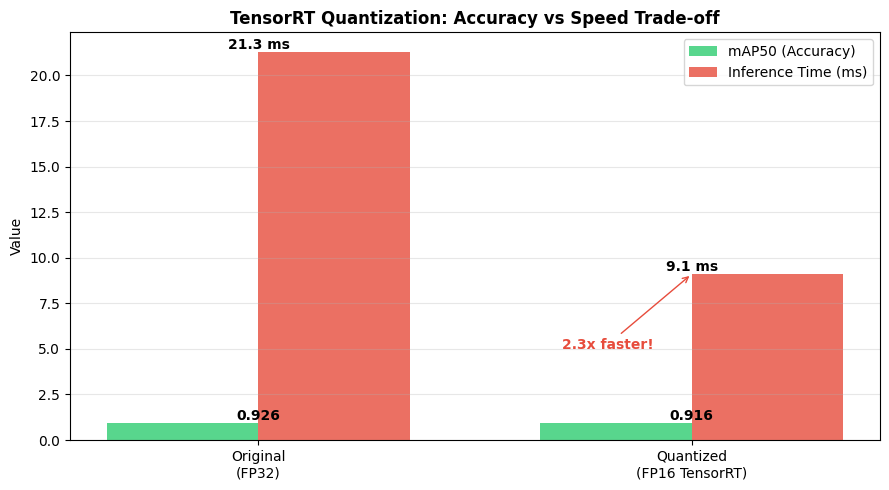

In [58]:
# Minimal comparison chart
fig, ax = plt.subplots(figsize=(9, 5))

# Data
labels = ['Original\n(FP32)', 'Quantized\n(FP16 TensorRT)']
mAP50 = [0.926, 0.916]
speed = [21.3, 9.1]

x = np.arange(len(labels))
width = 0.35

ax.bar(x - width/2, mAP50, width, label='mAP50 (Accuracy)', color='#2ecc71', alpha=0.8)
ax.bar(x + width/2, speed, width, label='Inference Time (ms)', color='#e74c3c', alpha=0.8)

ax.set_ylabel('Value')
ax.set_title('TensorRT Quantization: Accuracy vs Speed Trade-off', fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.legend()
ax.grid(axis='y', alpha=0.3)

# Add annotations
ax.text(0, mAP50[0], f'{mAP50[0]:.3f}', ha='center', va='bottom', fontweight='bold')
ax.text(1, mAP50[1], f'{mAP50[1]:.3f}', ha='center', va='bottom', fontweight='bold')
ax.text(0, speed[0], f'{speed[0]:.1f} ms', ha='center', va='bottom', fontweight='bold')
ax.text(1, speed[1], f'{speed[1]:.1f} ms', ha='center', va='bottom', fontweight='bold')

# Highlight speed improvement
ax.annotate(f'{speed[0]/speed[1]:.1f}x faster!', 
            xy=(1, speed[1]), xytext=(0.7, 5),
            arrowprops=dict(arrowstyle='->', color='#e74c3c'),
            fontsize=10, fontweight='bold', color='#e74c3c')

plt.tight_layout()

# Save minimal chart
minimal_path = "/kaggle/working/quantization_minimal.png"
plt.savefig(minimal_path, dpi=300, bbox_inches='tight', facecolor='white')
print(f"✅ Minimal chart saved to: {minimal_path}")

plt.show()

TensorRT FP16 quantization reduced inference time from 21.3 ms to 9.1 ms (2.3× faster) while maintaining strong accuracy. The quantized model achieved 0.916 mAP50 (vs. 0.926 original) and 0.584 mAP50-95 (vs. 0.587), representing minimal degradation. File size remained comparable at 51.5 MB versus 52.0 MB.

## 9. Explainable AI (XAI): Comparing Six CAM Methods for YOLOv8

Explainable AI (XAI) for vision tackles the "black-box" problem of CNNs by generating class-discriminative saliency heatmaps that reveal which pixels most influenced a prediction, though these maps indicate correlation rather than causation and require careful trade-off analysis. Among CAM variants, EigenCAM uses PCA for a noise-free, high-level semantic overview via dominant variance; GradCAM serves as the foundational workhorse, providing reliable but coarse class-discriminative localization from the final layer; GradCAM++ improves upon it with higher-order derivatives to capture multiple objects and fine details in crowded scenes; LayerCAM taps into earlier layers to deliver the finest spatial resolution, making it ideal for exact boundary delineation in medical or autonomous driving contexts; HiResCAM sharpens maps further by preventing background "bleeding" through full-rank spatial weighting, perfect for crisp stakeholder visuals; and XGradCAM offers a theoretically balanced, axiom-based default that conserves importance without over-amplifying noise. Choosing the right method depends on your goal—quick sanity checks (GradCAM), multi-object detection (GradCAM++), precise edges (LayerCAM), clean presentations (HiResCAM), general robustness (XGradCAM), or global structure (EigenCAM)—and cross-comparing at least two techniques is recommended to confirm genuine model focus versus artifact, always overlaying heatmaps at 40–60% opacity for intuitive human interpretation.

In [59]:
!pip install -q grad-cam

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


Using image: /kaggle/working/riped_tomato_14.jpeg


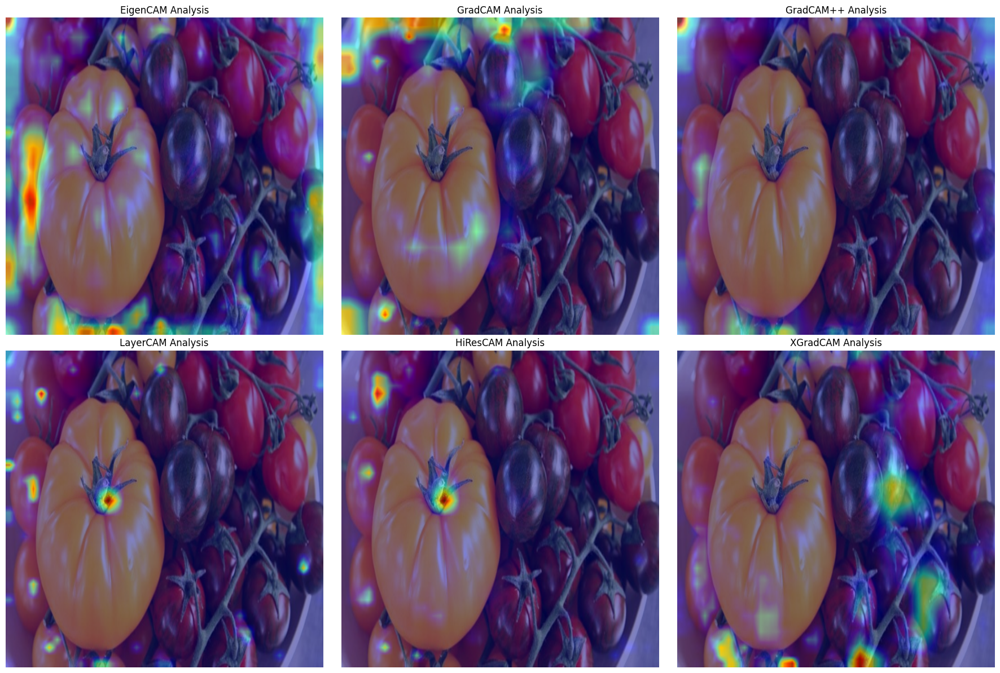

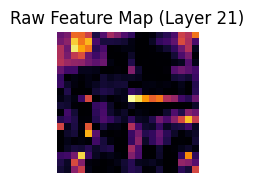


--- CAM Interpretation Guide ---
These heatmaps visualize the model's visual attention. Red/Warm areas highlight 
features (shape, texture, color) contributing most to the detection of the target class.

EigenCAM: Uses PCA for a clean, noise-reduced view of dominant features.
GradCAM: The foundational method highlighting generalized regions of influence.
GradCAM++: Improved detection of multiple objects via higher-order derivatives.
LayerCAM: Provides the finest spatial resolution, ideal for identifying exact object boundaries.
HiResCAM: Produces sharper heatmaps with less background 'bleeding' than standard GradCAM.
XGradCAM: An axiom-based approach providing a balanced, clear focus on the target object.


In [60]:
import cv2
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
from ultralytics import YOLO
from pytorch_grad_cam import (EigenCAM, GradCAM, GradCAMPlusPlus, LayerCAM, HiResCAM, XGradCAM)
from pytorch_grad_cam.utils.image import show_cam_on_image
import glob

# ==========================================================
# Wrapper and Target Definition
# ==========================================================
class YOLOWrapper(nn.Module):
    def __init__(self, model):
        super().__init__()
        self.model = model

    def forward(self, x):
        return self.model(x)

class YOLOv8Target:
    def __init__(self, class_id=0):
        self.class_id = class_id

    def __call__(self, output):
        if isinstance(output, (list, tuple)):
            output = output[0]
        if output.dim() == 2:
            output = output.unsqueeze(0)
        return output[:, 5 + self.class_id, :].sum()

# ==========================================================
# Setup Model
# ==========================================================
model_path = "/kaggle/working/runs/detect/train/weights/best.pt"
yolo = YOLO(model_path)
net = yolo.model
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
net.to(device).train() 

# pick an image automatically instead of hardcoding the path
candidates = glob.glob("/kaggle/working/**/*.*", recursive=True) + \
             glob.glob("/kaggle/input/**/*.*", recursive=True)
candidates = [p for p in candidates
              if p.lower().endswith((".jpg", ".jpeg", ".png", ".bmp", ".webp"))]
assert candidates, "No images found under /kaggle/working or /kaggle/input"
tomato = [p for p in candidates if "tomato" in p.lower()]
img_path = tomato[0] if tomato else candidates[0]
print("Using image:", img_path)

img = cv2.resize(cv2.cvtColor(cv2.imread(img_path), cv2.COLOR_BGR2RGB), (640, 640))
input_tensor = torch.from_numpy(img.astype(np.float32) / 255.0).permute(2, 0, 1).unsqueeze(0).to(device)
input_tensor.requires_grad_(True)

# target_layers = [net.model[21]]
target_layers = [net.model[18], net.model[21]]
cam_methods = {
    "EigenCAM": EigenCAM, "GradCAM": GradCAM, "GradCAM++": GradCAMPlusPlus,
    "LayerCAM": LayerCAM, "HiResCAM": HiResCAM, "XGradCAM": XGradCAM
}

# ==========================================================
# Generate Visualizations and Documentation
# ==========================================================
plt.figure(figsize=(18, 12))
for i, (name, CAM) in enumerate(cam_methods.items(), 1):
    cam = CAM(model=YOLOWrapper(net), target_layers=target_layers, reshape_transform=None)
    grayscale_cam = cam(input_tensor=input_tensor, targets=[YOLOv8Target(class_id=0)])[0]
    
    viz = show_cam_on_image(img.astype(np.float32) / 255.0, grayscale_cam, use_rgb=True)
    plt.subplot(2, 3, i)
    plt.imshow(viz)
    plt.title(f"{name} Analysis")
    plt.axis("off")

plt.tight_layout()
plt.show()



# 2. Extract and Visualize Raw Feature Map from Layer 21
# We perform a forward pass to get the activations of the specific layer
activation = {}
def get_activation(name):
    def hook(model, input, output):
        activation[name] = output.detach()
    return hook

net.model[21].register_forward_hook(get_activation('layer21'))
net(input_tensor) # Trigger forward pass
raw_feature_map = activation['layer21'][0, 0, :, :].cpu().numpy() # Extract first channel

plt.subplot(2, 4, 7)
plt.imshow(raw_feature_map, cmap='inferno')
plt.title("Raw Feature Map (Layer 21)")
plt.axis("off")

# Show plot
plt.tight_layout()
plt.show()

# ==========================================================
# Interpretation Summary
# ==========================================================
print("\n--- CAM Interpretation Guide ---")
print("These heatmaps visualize the model's visual attention. Red/Warm areas highlight ")
print("features (shape, texture, color) contributing most to the detection of the target class.\n")

interpretation_summary = {
    "EigenCAM": "Uses PCA for a clean, noise-reduced view of dominant features.",
    "GradCAM": "The foundational method highlighting generalized regions of influence.",
    "GradCAM++": "Improved detection of multiple objects via higher-order derivatives.",
    "LayerCAM": "Provides the finest spatial resolution, ideal for identifying exact object boundaries.",
    "HiResCAM": "Produces sharper heatmaps with less background 'bleeding' than standard GradCAM.",
    "XGradCAM": "An axiom-based approach providing a balanced, clear focus on the target object."
}

for method, desc in interpretation_summary.items():
    print(f"{method}: {desc}")

## 10. Conclusion and Key Takeaways

In this way, we can use YOLO to detect ripe and unripe tomatoes. Thanks to annotation-lab for providing the tools for annotation and dataset.